# 04 Payoff and ADUs by 2031

Logic: `pipeline/tract/payoff.py`, `forecast.py`, `migration.py`, `rollup.py`, `viz.py`. Every number they use is in `shared/assumptions.json` (keys starting with `tract.` plus the two mortgage rates).

**Outputs the tool reads**: `payoff_tract.csv`, `forecast_town.csv`, `county_rollup.csv`. Extra tables go to `processed/5500/`.

In [1]:
import sys
from pathlib import Path

import pandas as pd

ROOT = Path.cwd().parents[1] if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 20)
pd.set_option("display.precision", 3)
import matplotlib.pyplot as plt

plt.rcParams["figure.dpi"] = 60   # keeps the notebook small. Saved figures use 120 dpi

from pipeline.tract import forecast, migration, payoff, plots, rollup, viz

## 1. Does a 600 sq ft unit pay off?

- Cost: 600 sq ft x $175 / $250 / $300 per sq ft + 15% soft costs, all borrowed over 30 years
- Rate: 6.53% (2026 average of weekly PMMS) in the main run. 7.18% (latest week) in the sensitivity table
- Rent: a 600 sq ft unit is a 1-bedroom, so the test uses a 1-bedroom rent (`rent_b1`, the same column the tool uses)
- Net rent = rent x (1 - 30%). yes = covers the mid payment. maybe = covers the low payment or is within 10% of the mid one

In [2]:
p = payoff.run()
pd.Series(p['summary']).drop(['count', 'build_cost', 'monthly_payment', 'breakeven_rent', 'pop_share'])

rent_basis              rent_b1
rate                      0.065
rate_now                  0.072
tracts_with_rent           3445
tracts                     3445
share_yes                 0.103
share_maybe                0.26
share_no                  0.636
share_yes_all_units       0.203
share_yes_safmr           0.165
share_yes_rate_now        0.073
safmr_tract_coverage        1.0
dtype: object

In [3]:
pd.DataFrame({'build cost': p['summary']['build_cost'], 'monthly payment': p['summary']['monthly_payment'],
              'rent needed': p['summary']['breakeven_rent']}).round(0)

,build cost,monthly payment,rent needed
low,120750.0,766.0,1094.0
mid,172500.0,1094.0,1562.0
high,207000.0,1312.0,1875.0


### Rent bases compared

- `rent_b1`: tract median rent x the county ratio of 1-bedroom to all-unit rent (B25031). Every tract has one
- `rent_b1_tract`: the raw tract 1-bedroom median. Blank in 1 tract of 3 and noisy
- `safmr_1br`: HUD Small Area FMR, FY2026, by ZIP, averaged over each tract's ZIPs. It is the 40th percentile of recent movers, so it runs higher than ACS medians, which include long-time tenants
- `median_rent_all`: all units, the basis of the first report

In [4]:
p['basis_summary'].round(3)

,rent_basis,label,tracts,median,median_ratio_to_headline,corr_with_headline
0,rent_b1,"1-bedroom, tract median x county B25031 ratio ...",3445,956.00,1.000,1.000
1,rent_b1_tract,"1-bedroom, raw tract B25031 median",2146,906.00,1.036,0.879
2,safmr_1br,"1-bedroom, HUD SAFMR FY2026 by ZIP",3445,1178.01,1.249,0.780
3,median_rent_all,"All units, tract median B25064 (first report)",3261,1149.00,1.216,0.988


### Sensitivity: share of tracts that pay (yes), by rent basis, rate and cost

In [5]:
sens = p['sensitivity']
(sens.pivot_table(index=['rent_basis', 'rate_name'], columns='cost_level', values='share_yes')[['low', 'mid', 'high']] * 100).round(1)

cost_level                     low   mid  high
rent_basis      rate_name                     
median_rent_all 2026 average  55.9  20.3   9.2
                latest week   48.1  15.8   6.8
rent_b1         2026 average  36.4  10.3   4.0
                latest week   30.6   7.3   2.8
rent_b1_tract   2026 average  33.7  11.8   4.3
                latest week   27.7   9.0   3.4
safmr_1br       2026 average  60.8  16.5   6.6
                latest week   50.8  11.7   4.1

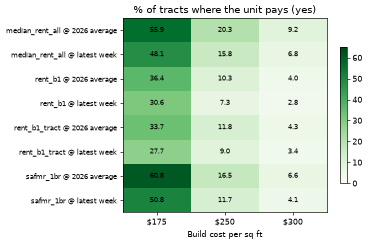

In [6]:
plots.sensitivity_heat(sens);

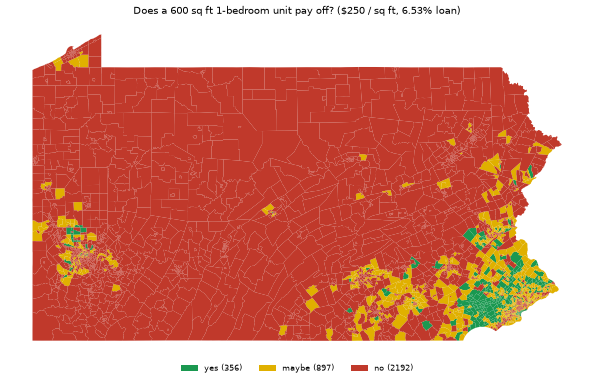

In [7]:
s = p['summary']
plots.payoff_map(p['payoff'], f"Does a 600 sq ft 1-bedroom unit pay off? ($250 / sq ft, {s['rate']:.2%} loan)");

### Counties with the most tracts that pay

In [8]:
payoff.county_table(p['payoff']).sort_values('yes', ascending=False).head(10).round(3)

,county,tracts,yes,maybe,median_rent_b1,share_yes,share_yes_or_maybe
45,42091,219,76,116,1467.0,0.347,0.877
50,42101,408,73,207,1242.0,0.179,0.686
14,42029,124,67,43,1604.0,0.540,0.887
8,42017,147,48,79,1375.0,0.327,0.864
22,42045,152,29,77,1176.0,0.191,0.697
1,42003,394,22,89,965.0,0.056,0.282
38,42077,81,13,31,1137.0,0.160,0.543
35,42071,116,7,51,1093.0,0.060,0.500
47,42095,74,7,36,1123.5,0.095,0.581
44,42089,51,2,16,982.0,0.039,0.353


## 2. Lots with room and town rules (inputs to the ADU arithmetic)

- `lot_rollup`: the lot tool's results for every 1 to 4 unit lot in Philadelphia and Pittsburgh, summed to tract, city and county, and compared with the retired raster pilot
- `room`: share of lots with room for a 600 sq ft unit (state-reform setbacks). Measured in the two cities, modelled elsewhere with a range. Validated by holding out one city
- `legal`: each town's legal class from the rule files in `shared/rules`. Towns without a file are "unknown"

,place,lots,share_legal_today,share_fit600_today,share_fit600_state_reform,share_garage
0,philadelphia,459998,0.012,0.000,0.075,0.015
1,pittsburgh,92081,1.000,0.412,0.459,0.228


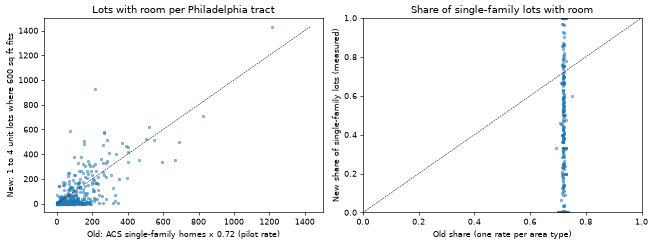

In [9]:
from pipeline.tract import legal, lot_rollup, room

lr = lot_rollup.run()
lr['city'][['place', 'lots', 'share_legal_today', 'share_fit600_today', 'share_fit600_state_reform', 'share_garage']]

In [10]:
pd.Series(lr['lot_compare']).round(3)

matched_lots                               25367.000
share_fit_old_raster                           0.486
share_fit_new_vector                           0.400
agree                                          0.792
old_yes_new_no                                 0.147
old_no_new_yes                                 0.061
single_family_detached_share_of_matched        0.960
pilot_lots_philadelphia                    26269.000
dtype: float64

In [11]:
pd.Series(lr['tract_compare']).round(3)

tracts                                       385.000
corr_count_old_fit_vs_new_fit600_state         0.724
mean_diff_count_new_minus_old                -27.865
corr_share_old_vs_new_sfd                      0.037
old_share_sd                                   0.005
new_sfd_share_sd                               0.319
mean_old_share                                 0.720
mean_new_sfd_share                             0.354
mean_diff_share_new_minus_old                 -0.365
tracts_with_sfd                              303.000
sum_old_lots_total_acs_sfd                 63206.000
sum_new_sfd_lots                           26949.000
sum_new_lots                              459998.000
sum_old_lots_fit                           45469.000
sum_new_sfd_fit600_state_reform            14453.000
sum_new_fit600_state_reform                34741.000
sum_new_room600_today_setbacks             22024.000
dtype: float64

In [12]:
rm = room.run()
rm['cross_city'].round(3)

,test_city,model,r2,mae,mae_lot_weighted,bias,pooled_share_true,pooled_share_pred
0,philadelphia,lot_weighted_mean,-6.225,0.376,0.388,0.366,0.076,0.459
1,philadelphia,old_pilot_rate,-18.237,0.627,0.644,0.626,0.076,0.719
2,philadelphia,ridge,0.486,0.068,0.050,-0.010,0.076,0.049
3,philadelphia,gradient_boosting,0.004,0.122,0.120,0.066,0.076,0.150
4,pittsburgh,lot_weighted_mean,-2.588,0.353,0.387,-0.350,0.459,0.076
5,pittsburgh,old_pilot_rate,-1.831,0.310,0.279,0.294,0.459,0.719
6,pittsburgh,ridge,0.458,0.126,0.123,0.026,0.459,0.499
7,pittsburgh,gradient_boosting,0.382,0.138,0.143,-0.043,0.459,0.406


In [13]:
rm['block_cv'].round(3)

,model,r2,mae,mae_lot_weighted,bias,pooled_share_true,pooled_share_pred
0,lot_weighted_mean,-0.019,0.168,0.158,-0.029,0.139,0.140
1,old_pilot_rate,-6.514,0.555,0.583,0.551,0.139,0.719
2,ridge,0.757,0.076,0.060,0.005,0.139,0.141
3,gradient_boosting,0.749,0.070,0.057,0.004,0.139,0.141


tracts                                  3445
measured_tracts                          513
modelled_tracts                         2932
modelled_outside_training_range         1780
lots_est                           4482651.0
lots_room_low                      1491667.0
lots_room_mid                      2880242.0
lots_room_high                     3550530.0
lots_room_measured                   76970.0
lots_room_old_pilot                2586637.0
share_room_mid_modelled                0.713
modelled_clipped_at_1                    459
dtype: object

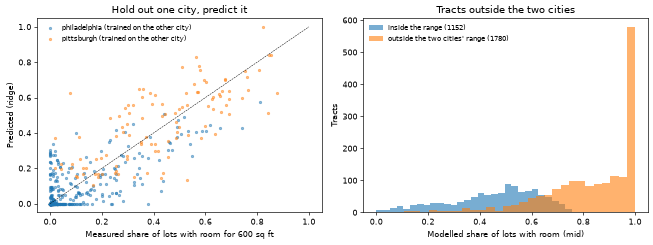

In [14]:
room.figure(rm['cross_city_pred'], rm['tracts'])
pd.Series(rm['summary']['statewide']).drop('by_old_stratum')

In [15]:
lg = legal.build()
lg[lg.has_rule_file][['name', 'review', 'adu_status', 'legal_class']].sort_values('legal_class')

,name,review,adu_status,legal_class
196,Pittsburgh city,verified,allowed_by_right,by_right
737,Erie city,drafted,allowed_by_right,by_right
1002,Harrisburg city,verified,allowed_by_right,by_right
1082,Altoona city,verified,allowed_by_right,by_right
1591,Scranton city,verified,allowed_by_right,by_right
1710,Cranberry township,drafted,allowed_by_right,by_right
1882,State College borough,drafted,allowed_by_right,by_right
2349,Lower Paxton township,drafted,allowed_by_right,by_right
2425,Allentown city,verified,allowed_by_right,by_right
393,Philadelphia city,verified,conversion_only,conversion_only


## 3. Where did housing grow? Model and validation

- Target: log(decennial homes 2020 / 2010) per tract. Tracts with under 100 homes in 2010 are left out
- Features: 2010 values only. IRS county migration is tested as an extra feature
- Models: state median (baseline), ridge, random forest, gradient boosting (absolute-error loss)
- Spatial cross-validation: whole counties held out, and 40 km grid blocks held out. Random 5-fold is shown only to show how much it flatters
- Rule: the model with the lowest county-held-out MAE is used. R2 is shown too, but a few crosswalk artifacts dominate it

In [16]:
f = forecast.run()
{k: v for k, v in f['summary'].items() if k != 'totals'}

{'model': 'gradient_boosting',
 'use_migration': False,
 'migration_gain_r2': 0.006407986391154696,
 'training_tracts': 3394,
 'target_median_growth': 0.013136399797402092,
 'conformal_halfwidth_log': 0.20395700032514597,
 'conformal_coverage_mean': 0.8983758532574428,
 'conformal_coverage_min': 0.8455882352941176,
 'quantile_gb': {'coverage': 0.7613435474366529,
  'median_width': 0.1704560037064319},
 'top4': ['log_units', 'log_workers', 'units_per_km2', 'dev_share'],
 'pa_pop_2024': 13018639.0,
 'room_source': 'room_tract.csv (measured in Philadelphia and Pittsburgh, modelled elsewhere)',
 'legal_source': 'town_legal_class.csv (shared/rules town files, unknown elsewhere)',
 'totals_old_inputs': {'current': {'by_2031.low': 247.93626886216617,
   'by_2031.mid': 896.3196652572958,
   'by_2031.high': 2332.0860383871154,
   'per_year.low': 49.587253772433236,
   'per_year.mid': 179.26393305145916,
   'per_year.high': 466.4172076774231,
   'per_100k_per_year.low': 0.38089429910786554,
   '

In [17]:
f['cv'].round(3)

,scheme,model,r2_pooled,mae,r2_fold_mean
0,random_5fold,median_baseline,-0.002,0.107,NaN
1,random_5fold,ridge,0.191,0.115,NaN
2,random_5fold,random_forest,0.225,0.093,NaN
3,random_5fold,gradient_boosting,0.164,0.088,NaN
4,county_blocks,median_baseline,-0.003,0.107,-0.008
5,county_blocks,ridge,0.194,0.120,0.214
6,county_blocks,random_forest,0.216,0.100,0.202
7,county_blocks,gradient_boosting,0.202,0.092,0.256
8,grid_40km_blocks,median_baseline,-0.002,0.107,-0.007
9,grid_40km_blocks,ridge,0.197,0.116,0.205


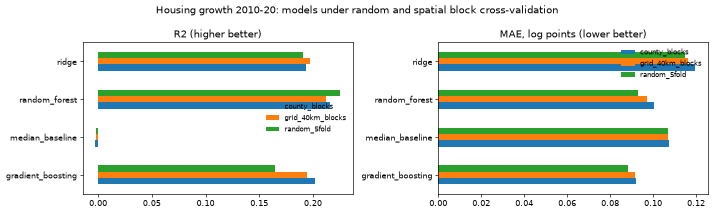

In [18]:
plots.model_compare(f['cv']);

### Temporal backtest

- Train on the change from 2010-14 to 2015-19 (ACS homes, features at 2010-14). Predict the change from 2015-19 to 2020-24 (features at 2015-19). Score against what the 2020-24 ACS reports
- Baselines: each tract keeps its own earlier change (last-period rate), and the earlier median
- `beyond_moe` columns score only tracts whose change is bigger than its ACS margin of error

In [19]:
f['backtest'].round(3)

,model,r2,mae,corr,r2_beyond_moe,corr_beyond_moe,tracts_beyond_moe
0,median_of_earlier_period,-0.002,0.120,-0.000,-0.009,0.000,958
1,last_period_rate,-0.086,0.133,0.005,-0.043,0.013,958
2,ridge,0.025,0.117,0.194,0.020,0.230,958
3,random_forest,0.019,0.118,0.140,0.019,0.173,958
4,gradient_boosting,0.021,0.118,0.152,0.020,0.197,958


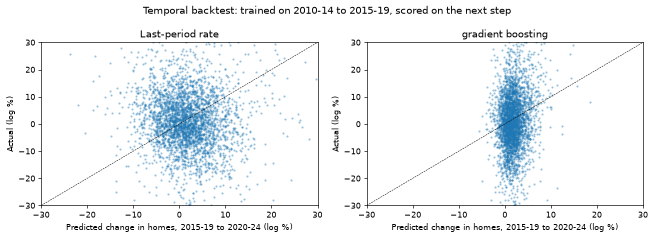

In [20]:
plots.backtest_scatter(f['backtest_detail'], f['summary']['model']);

### Prediction intervals

- Split conformal, 90%: half-width = a high quantile of the absolute county-held-out errors
- Coverage is checked fold by fold, with the half-width taken from the other folds only

In [21]:
f['coverage'].round(3)

,fold,halfwidth,coverage,n
0,0,0.187,0.846,680
1,1,0.215,0.926,679
2,2,0.221,0.947,679
3,3,0.189,0.857,679
4,4,0.210,0.916,677


### Permutation importance on held-out counties, and partial dependence for the top 4

In [22]:
f['importance'].round(4)

,importance,fold_sd
log_units,0.691,0.364
log_workers,0.522,0.231
units_per_km2,0.041,0.009
dev_share,0.028,0.022
x,0.012,0.005
y,0.007,0.006
log_jobs,0.006,0.004
devhi_share,0.003,0.005
jobs_per_unit,0.002,0.017
log_area,0.002,0.007


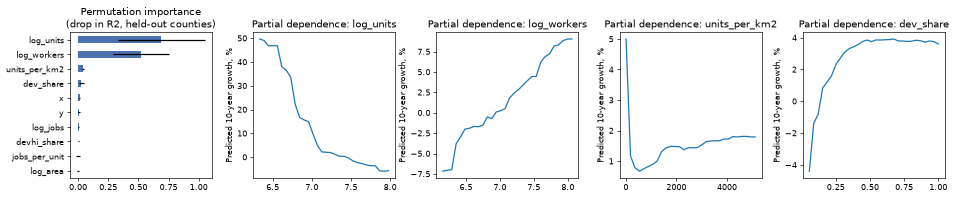

In [23]:
plots.importance_pdp(f['importance'], f['pdp']);

### IRS migration

- County net movers per 1,000 residents, before (2012-19) and after (2020-23)
- As a model feature it did not clear the bar (see `migration_gain_r2` above). It stays as context

In [24]:
panel = pd.read_csv(ROOT / 'data/processed/tract_panel.csv', dtype={'GEOID': str, 'county': str})
mig = migration.periods(migration.load(), panel)
mig.describe().round(2)

,before,after,change
count,67.00,67.00,67.00
mean,-1.10,1.61,2.71
std,2.78,4.27,3.13
min,-8.26,-14.81,-6.55
25%,-2.70,-0.40,0.99
50%,-1.30,1.12,2.55
75%,0.38,3.26,3.89
max,5.56,18.34,15.58


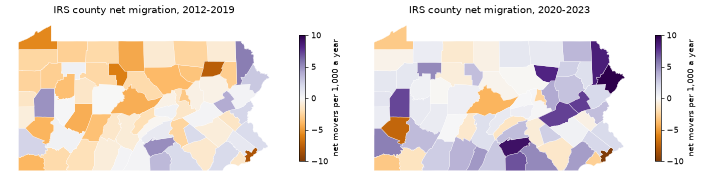

In [25]:
plots.migration_map(mig);

## 4. ADUs by 2031

- ADUs = people x permit rate x payoff weight x lots index x demand x town rule x 5 years, capped at lots with room (`room_tract.csv`: measured in the two cities, modelled elsewhere)
- Permit rate 26 / 53.5 / 81 per 100,000 people a year (low / mid / high)
- Today: each town's legal class from the rule files. By right 1.0. Discretionary, family-only, conversion-only and unknown 0.02 / 0.05 / 0.10. None 0 / 0.005 / 0.01
- HB 2186: every town by right. SB 1346: every town by right except Philadelphia and Pittsburgh (the MPC does not reach them)
- Both bills die on Nov 30, 2026 if not enacted
- This is scenario arithmetic, not a fitted model. Pennsylvania has no ADU permit series: the Census permit survey does not split out ADUs, and Philadelphia has about 10 legal ADUs since 2012. So the low-high range shows the assumptions, not statistical error

In [26]:
f['totals'].round(1)

by_2031                   per_year                 per_100k_per_year            
            low      mid     high      low     mid    high               low   mid  high
rule                                                                                    
current   314.3   1012.1   2451.3     62.9   202.4   490.3               0.5   1.6   3.8
hb2186   6539.8  13454.8  20366.6   1308.0  2691.0  4073.3              10.0  20.7  31.3
sb1346   6431.4  13238.5  20056.4   1286.3  2647.7  4011.3               9.9  20.3  30.8

Old vs new inputs: the same arithmetic with the pilot room estimate and the 12-town list, and each mix (mid, by 2031)

In [27]:
f['variants'].pivot(index='inputs', columns='rule', values='mid').round(0)

rule,current,hb2186,sb1346
inputs,,,
"new room, 12-town list",868.0,13455.0,13238.0
"new: new room, rule-file classes",1012.0,13455.0,13238.0
"old: pilot room, 12-town list",896.0,13144.0,12839.0
"pilot room, rule-file classes",1046.0,13144.0,12839.0


In [28]:
f['legal_coverage'].round(3)

,legal_class,towns,towns_drafted,pop,pop_drafted,share_of_pa_pop
5,unknown,2533,0,9.275e+06,0.000,0.712
1,conversion_only,2,0,1.625e+06,0.000,0.125
0,by_right,9,4,8.238e+05,223655.247,0.063
4,none,18,6,7.815e+05,214611.572,0.060
3,family_only,9,6,4.598e+05,265347.005,0.035
2,discretionary,1,0,5.417e+04,0.000,0.004


Mid ADUs by 2031 by the town's legal class today and whether it has a rule file

In [29]:
f['by_rule']

,rule,current,hb2186,sb1346
adu_rule,coded,,,
by_right,rule file,404.0,404.0,404.0
conversion_only,rule file,12.0,237.0,20.0
discretionary,rule file,3.0,69.0,69.0
family_only,rule file,23.0,465.0,465.0
none,rule file,5.0,983.0,983.0
unknown,no rule file,565.0,11297.0,11297.0


In [30]:
t = f['towns']
t[t.town_geoid.isin([forecast.PHILADELPHIA, forecast.PITTSBURGH])][['name', 'legal_class', 'rule', 'adus_low', 'adus_mid', 'adus_high']]

,name,legal_class,rule,adus_low,adus_mid,adus_high
366,Pittsburgh city,by_right,current,60.2,123.5,185.9
367,Pittsburgh city,by_right,hb2186,60.2,123.5,185.9
368,Pittsburgh city,by_right,sb1346,60.2,123.5,185.9
5913,Philadelphia city,conversion_only,current,2.2,11.4,34.5
5914,Philadelphia city,conversion_only,hb2186,110.6,227.7,344.7
5915,Philadelphia city,conversion_only,sb1346,2.2,11.4,34.5


In [31]:
t[t.rule == 'hb2186'].nlargest(10, 'adus_mid')[['name', 'legal_class', 'review', 'pop', 'adus_low', 'adus_mid', 'adus_high']].round(0)

,name,legal_class,review,pop,adus_low,adus_mid,adus_high
5914,Philadelphia city,conversion_only,verified,1.580e+06,111.0,228.0,345.0
1441,Northampton township,none,verified,3.992e+04,64.0,133.0,201.0
367,Pittsburgh city,by_right,verified,3.048e+05,60.0,124.0,186.0
5446,Lower Merion township,family_only,verified,6.417e+04,55.0,113.0,171.0
3160,Haverford township,none,verified,5.087e+04,49.0,101.0,153.0
3202,Radnor township,none,drafted,3.372e+04,48.0,98.0,148.0
5545,Upper Providence township,unknown,none,2.467e+04,44.0,92.0,138.0
1414,Middletown township,none,verified,4.579e+04,44.0,90.0,137.0
1408,Lower Makefield township,none,verified,3.348e+04,44.0,90.0,136.0
2218,Tredyffrin township,unknown,todo,3.192e+04,42.0,87.0,131.0


In [32]:
permits = pd.read_csv(ROOT / 'data/processed/permits_county.csv')
recent = permits[permits.year >= permits.year.max() - 4].groupby('year').units_total.sum()
print(recent)
print('HB 2186 mid per year / recent average permits:', round(f['totals'].loc['hb2186', ('per_year', 'mid')] / recent.mean(), 3))

year
2021    47894
2022    28149
2023    25320
2024    24810
2025    25709
Name: units_total, dtype: int64
HB 2186 mid per year / recent average permits: 0.089


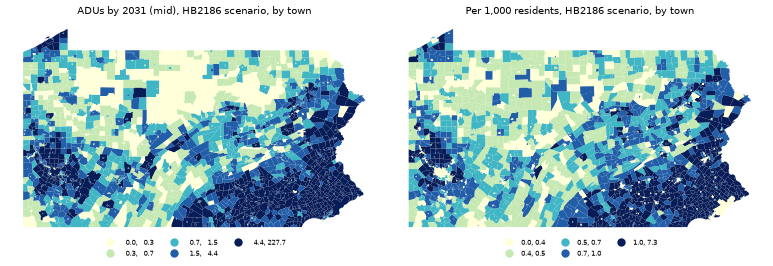

In [33]:
plots.forecast_map(f['towns']);

## 5. County roll-up and the linked view

In [34]:
c = rollup.run()
c.sort_values('adus_mid_hb2186', ascending=False)[['name', 'tracts', 'tracts_pays_yes', 'adus_mid_current', 'adus_mid_hb2186', 'adus_mid_sb1346']].head(10).round(1)

,name,tracts,tracts_pays_yes,adus_mid_current,adus_mid_hb2186,adus_mid_sb1346
45,Montgomery,219,76,74.4,1614.3,1614.3
14,Chester,124,67,76.9,1538.1,1538.1
8,Bucks,147,48,50.5,1403.0,1403.0
1,Allegheny,394,22,169.7,1153.7,1153.7
22,Delaware,152,29,29.4,767.7,767.7
35,Lancaster,116,7,35.8,727.7,727.7
38,Lehigh,81,13,71.4,535.1,535.1
66,York,108,1,26.6,533.0,533.0
47,Northampton,74,7,23.6,472.7,472.7
5,Berks,107,1,20.7,425.0,425.0


In [35]:
viz.run()

{'html_kb': 614.0947265625, 'spec_kb': 561.736328125, 'tracts': 3445}

The linked view is `musa5500/figures/tract_explorer.html`. Click a county, then drag a box on the scatter. The bars, histogram and table follow.